# ECG Lens: End-to-End ECG Prediction Pipeline

This notebook implements the inference pipeline for ECG abnormal
heartbeat detection using the MIT-BIH Arrhythmia Database.

The pipeline loads a saved machine-learning ensemble, preprocesses
an ECG recording, automatically detects heartbeat locations,
extracts the required features, and predicts heartbeat classes.

The predictions are compared with expert annotations only during
evaluation, not during inference.

In [2]:
from pathlib import Path
import joblib

# Find the attached model artifact in Kaggle inputs
matches = list(
    Path("/kaggle/input").rglob("ecg_lens_model_bundle.joblib")
)

if not matches:
    raise FileNotFoundError(
        "Model bundle not found. Check that the model input "
        "is attached to this Kaggle notebook."
    )

model_path = matches[0]

print("Model found at:", model_path)

# Load the saved bundle
model_bundle = joblib.load(model_path)

print("\nModel loaded successfully!")
print("Project:", model_bundle["project_name"])
print("Selected model:", model_bundle["model_name"])
print("Expected features:", model_bundle["n_features"])
print("Classes:", model_bundle["class_order"])

Model found at: /kaggle/input/models/peace304/ecg-lens-hybrid-voting-ensemble/scikitlearn/default/1/ecg_lens_model_bundle.joblib

Model loaded successfully!
Project: ECG Lens
Selected model: SVM + XGBoost + AdaBoost Voting Ensemble
Expected features: 226
Classes: ['N', 'S', 'V', 'F']


## 2. Load a Held-Out ECG Recording

We will use MIT-BIH record 213 to demonstrate the prediction pipeline. The recording will be loaded using WFDB, and the MLII lead will be selected to match the lead used during model training.

**Important:** The model must eventually make predictions from automatically detected heartbeat locations. Expert annotations will be reserved for evaluation, not used to generate predictions.

In [5]:
%pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.6 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy as np
import wfdb

# Select a recording from the held-out test group
record_id = "213"

record = wfdb.rdrecord(
    record_id,
    pn_dir="mitdb/1.0.0"
)

# Identify the MLII lead used during training
lead_names = [name.strip().upper() for name in record.sig_name]

if "MLII" not in lead_names:
    raise ValueError(
        f"MLII lead not found. Available leads: {record.sig_name}"
    )

lead_index = lead_names.index("MLII")

# Extract the ECG signal
ecg_raw = np.asarray(
    record.p_signal[:, lead_index],
    dtype=np.float64
)

sampling_rate = float(record.fs)
duration_seconds = len(ecg_raw) / sampling_rate

print("Recording loaded successfully!")
print("Record ID:", record_id)
print("Available leads:", record.sig_name)
print("Selected lead:", record.sig_name[lead_index])
print("Sampling rate:", sampling_rate, "Hz")
print("Signal samples:", len(ecg_raw))
print("Duration:", round(duration_seconds / 60, 2), "minutes")
print("Missing values:", np.isnan(ecg_raw).sum())

Recording loaded successfully!
Record ID: 213
Available leads: ['MLII', 'V1']
Selected lead: MLII
Sampling rate: 360.0 Hz
Signal samples: 650000
Duration: 30.09 minutes
Missing values: 0


## 3. ECG Preprocessing and Automatic Beat Detection

The raw ECG signal is filtered using a fourth-order Butterworth bandpass filter between 0.5 Hz and 40 Hz, matching the preprocessing used during model training.

We then use WFDB's XQRS detector to identify candidate heartbeat locations automatically. These detections will be used to prepare the input for ECG Lens.

WFDB processing module loaded successfully!
ECG filtering complete.
Filtered samples: 650000

Automatic heartbeat detection complete.
Detected beats: 3244
Approximate detected beats per minute: 107.8


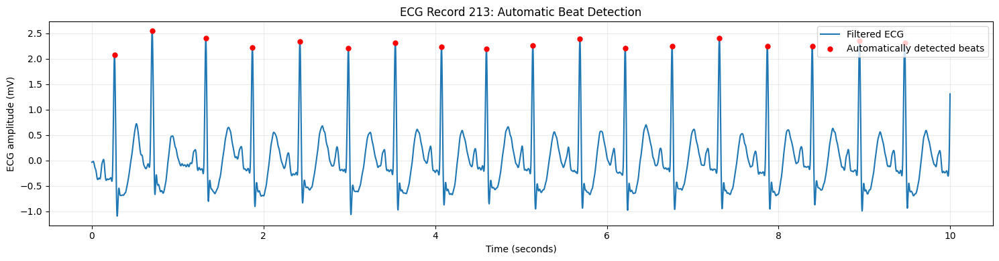

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
import wfdb
from wfdb import processing

print("WFDB processing module loaded successfully!")

# 1. Verify the sampling rate
if not np.isclose(sampling_rate, 360):
    raise ValueError(
        f"Expected 360 Hz based on training, got {sampling_rate} Hz."
    )

# 2. Filter the ECG signal using the training configuration
sos = butter(
    N=4,
    Wn=[0.5, 40.0],
    btype="bandpass",
    fs=sampling_rate,
    output="sos"
)

ecg_filtered = sosfiltfilt(sos, ecg_raw)

print("ECG filtering complete.")
print("Filtered samples:", len(ecg_filtered))

# 3. Detect heartbeats automatically using XQRS
beat_positions = processing.xqrs_detect(
    sig=ecg_raw,
    fs=sampling_rate,
    verbose=False
)

beat_positions = np.asarray(beat_positions, dtype=int)

print("\nAutomatic heartbeat detection complete.")
print("Detected beats:", len(beat_positions))
print(
    "Approximate detected beats per minute:",
    round(len(beat_positions) / duration_seconds * 60, 2)
)

# 4. Visualize the first 10 seconds
samples_to_plot = min(
    int(10 * sampling_rate),
    len(ecg_filtered)
)

time_axis = np.arange(samples_to_plot) / sampling_rate
visible_beats = beat_positions[beat_positions < samples_to_plot]

plt.figure(figsize=(15, 4))
plt.plot(time_axis, ecg_filtered[:samples_to_plot],
         label="Filtered ECG")
plt.scatter(
    visible_beats / sampling_rate,
    ecg_filtered[visible_beats],
    color="red",
    s=25,
    label="Automatically detected beats",
    zorder=3
)
plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title(f"ECG Record {record_id}: Automatic Beat Detection")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Verify the Model's Expected Input Features

Before generating predictions, we will inspect the saved model bundle to confirm its feature schema, class ordering, and prediction components.

This prevents feature-order mismatches and ensures the inference pipeline is consistent with model training.

In [11]:
print("MODEL BUNDLE KEYS")
print("=" * 45)

for key, value in model_bundle.items():
    print(f"{key}: {type(value).__name__}")

print("\nMODEL CONFIGURATION")
print("=" * 45)

for key in ["project_name", "model_name", "n_features", "class_order"]:
    if key in model_bundle:
        print(f"{key}: {model_bundle[key]}")

print("\nPOSSIBLE FEATURE SCHEMAS")
print("=" * 45)

for key, value in model_bundle.items():
    if isinstance(value, (list, tuple)):
        if len(value) > 0 and isinstance(value[0], str):
            print(f"\n{key} — {len(value)} entries")
            print("First 15:", value[:15])

MODEL BUNDLE KEYS
project_name: str
model_name: str
model_selection_metric: str
validation_macro_f1: float
class_order: list
label_mapping: dict
feature_names: list
n_features: int
models: dict
boost_imputer: SimpleImputer
preprocessing_config: dict
voting_config: dict

MODEL CONFIGURATION
project_name: ECG Lens
model_name: SVM + XGBoost + AdaBoost Voting Ensemble
n_features: 226
class_order: ['N', 'S', 'V', 'F']

POSSIBLE FEATURE SCHEMAS

class_order — 4 entries
First 15: ['N', 'S', 'V', 'F']

feature_names — 226 entries
First 15: ['waveform_000', 'waveform_001', 'waveform_002', 'waveform_003', 'waveform_004', 'waveform_005', 'waveform_006', 'waveform_007', 'waveform_008', 'waveform_009', 'waveform_010', 'waveform_011', 'waveform_012', 'waveform_013', 'waveform_014']


## 5. Inspect Inference Configuration

We will inspect the saved feature schema, preprocessing parameters, model components, and voting rules. These settings will guide the implementation of the end-to-end inference pipeline and help prevent inconsistencies with training.

In [12]:
# 1. Inspect feature names around the boundaries
print("FEATURE SCHEMA")
print("=" * 55)

print("First 8 features:")
print(model_bundle["feature_names"][:8])

print("\nLast 15 features:")
print(model_bundle["feature_names"][-15:])

print("\nFeature count:", len(model_bundle["feature_names"]))

# 2. Inspect preprocessing configuration
print("\nPREPROCESSING CONFIGURATION")
print("=" * 55)

for key, value in model_bundle["preprocessing_config"].items():
    print(f"{key}: {value}")

# 3. Inspect voting configuration
print("\nVOTING CONFIGURATION")
print("=" * 55)

for key, value in model_bundle["voting_config"].items():
    print(f"{key}: {value}")

# 4. Inspect the saved prediction models
print("\nSAVED MODEL COMPONENTS")
print("=" * 55)

for name, model in model_bundle["models"].items():
    print(f"{name}: {type(model).__name__}")

# 5. Inspect label mapping
print("\nLABEL MAPPING")
print("=" * 55)
print(model_bundle["label_mapping"])

FEATURE SCHEMA
First 8 features:
['waveform_000', 'waveform_001', 'waveform_002', 'waveform_003', 'waveform_004', 'waveform_005', 'waveform_006', 'waveform_007']

Last 15 features:
['waveform_211', 'waveform_212', 'waveform_213', 'waveform_214', 'waveform_215', 'mean_amplitude', 'std_amplitude', 'min_amplitude', 'max_amplitude', 'peak_to_peak', 'rms_amplitude', 'qrs_peak_to_peak', 'qrs_rms', 'rr_previous_seconds', 'rr_next_seconds']

Feature count: 226

PREPROCESSING CONFIGURATION
sampling_rate_hz: 360
filter_type: Butterworth band-pass
filter_order: 4
low_cutoff_hz: 0.5
high_cutoff_hz: 40
zero_phase_filtering: True
segment_before_seconds: 0.2
segment_after_seconds: 0.4
samples_per_heartbeat: 216
paced_records_excluded: ['102', '104', '107', '217']

VOTING CONFIGURATION
models: ['linear_svm', 'xgboost', 'adaboost']
rule: majority_vote
tie_breaker: Use SVM prediction if it is among the tied leading classes; otherwise use the first tied class in class_order.

SAVED MODEL COMPONENTS
linea

## 6. Extract Features from Automatically Detected Heartbeats

Each detected heartbeat is converted into the same 226 features used during training:

- **216 waveform features:** samples from 0.2 seconds before to 0.4 seconds after the detected heartbeat.
- **8 summary features:** amplitude statistics, RMS amplitude, and QRS-region measurements.
- **2 RR-interval features:** time since the previous detected heartbeat and until the next detected heartbeat.

The feature columns are arranged according to the saved model's feature schema to prevent input-order mismatches. Missing RR intervals at recording boundaries are retained for the trained imputers to handle.

In [13]:
import numpy as np
import pandas as pd

def build_beat_feature_frame(
    filtered_signal,
    detected_positions,
    sampling_rate=360
):
    """Build training-compatible features for detected ECG beats."""

    config = model_bundle["preprocessing_config"]
    feature_names = model_bundle["feature_names"]

    # Verify compatibility with training
    if not np.isclose(
        sampling_rate, config["sampling_rate_hz"]
    ):
        raise ValueError(
            f"Expected {config['sampling_rate_hz']} Hz, "
            f"received {sampling_rate} Hz."
        )

    signal = np.asarray(filtered_signal, dtype=np.float64)
    positions = np.unique(
        np.asarray(detected_positions, dtype=int)
    )

    if len(positions) == 0:
        raise ValueError("No heartbeat positions were provided.")

    if not np.isfinite(signal).all():
        raise ValueError("ECG signal contains NaN or infinite values.")

    # Reproduce the training segment dimensions
    pre_samples = int(
        config["segment_before_seconds"] * sampling_rate
    )
    post_samples = int(
        config["segment_after_seconds"] * sampling_rate
    )
    expected_length = config["samples_per_heartbeat"]

    if pre_samples + post_samples != expected_length:
        raise ValueError("Segment dimensions do not match training.")

    # Keep only beats for which the complete waveform window exists.
    # Keep their original indices so RR intervals use all detected beats.
    valid_indices = np.flatnonzero(
        (positions >= pre_samples)
        & (positions + post_samples <= len(signal))
    )

    if len(valid_indices) == 0:
        raise ValueError(
            "No detected beats have complete waveform windows."
        )

    half_qrs_window = int(0.05 * sampling_rate)
    rows = []

    for idx in valid_indices:
        peak = positions[idx]

        start = peak - pre_samples
        end = peak + post_samples

        # Match the float32 heartbeat segments used during training
        segment = signal[start:end].astype(np.float32)

        if len(segment) != expected_length:
            continue

        # Training used segment indices 54:91 at 360 Hz
        qrs_region = segment[
            pre_samples - half_qrs_window:
            pre_samples + half_qrs_window + 1
        ]

        row = {}

        # 216 waveform sample features
        for j, value in enumerate(segment):
            row[f"waveform_{j:03d}"] = float(value)

        # 8 summary features — same calculations as training
        row.update({
            "mean_amplitude": float(np.mean(segment)),
            "std_amplitude": float(np.std(segment)),
            "min_amplitude": float(np.min(segment)),
            "max_amplitude": float(np.max(segment)),
            "peak_to_peak": float(np.ptp(segment)),
            "rms_amplitude": float(
                np.sqrt(np.mean(segment ** 2))
            ),
            "qrs_peak_to_peak": float(np.ptp(qrs_region)),
            "qrs_rms": float(
                np.sqrt(np.mean(qrs_region ** 2))
            ),
        })

        # RR intervals in seconds, calculated from detected beats
        row["rr_previous_seconds"] = (
            float((positions[idx] - positions[idx - 1]) / sampling_rate)
            if idx > 0 else np.nan
        )

        row["rr_next_seconds"] = (
            float((positions[idx + 1] - positions[idx]) / sampling_rate)
            if idx < len(positions) - 1 else np.nan
        )

        rows.append(row)

    # Enforce the exact saved feature order
    features = pd.DataFrame(rows)
    features = features.reindex(columns=feature_names)

    if features.shape[1] != model_bundle["n_features"]:
        raise ValueError(
            f"Expected {model_bundle['n_features']} features, "
            f"got {features.shape[1]}."
        )

    if features.empty:
        raise ValueError("Feature extraction produced no valid rows.")

    valid_positions = positions[valid_indices[:len(features)]]

    assert list(features.columns) == feature_names

    return features, valid_positions


# Build features from the previously filtered ECG
ecg_features, prediction_positions = build_beat_feature_frame(
    filtered_signal=ecg_filtered,
    detected_positions=beat_positions,
    sampling_rate=sampling_rate
)

print("Feature extraction successful!")
print("Detected beats:", len(beat_positions))
print("Beats with complete windows:", len(ecg_features))
print("Feature matrix shape:", ecg_features.shape)
print(
    "Missing previous RR intervals:",
    ecg_features["rr_previous_seconds"].isna().sum()
)
print(
    "Missing next RR intervals:",
    ecg_features["rr_next_seconds"].isna().sum()
)

print("\nSummary feature preview:")
display(
    ecg_features[
        [
            "mean_amplitude",
            "peak_to_peak",
            "qrs_peak_to_peak",
            "rr_previous_seconds",
            "rr_next_seconds"
        ]
    ].head()
)

Feature extraction successful!
Detected beats: 3244
Beats with complete windows: 3243
Feature matrix shape: (3243, 226)
Missing previous RR intervals: 1
Missing next RR intervals: 0

Summary feature preview:


,mean_amplitude,peak_to_peak,qrs_peak_to_peak,rr_previous_seconds,rr_next_seconds
0,-0.103217,3.173301,3.173301,NaN,0.438889
1,0.074779,3.215663,3.215663,0.438889,0.625000
2,0.036312,3.207247,3.207247,0.625000,0.541667
3,-0.017683,3.125611,3.125611,0.541667,0.555556
4,0.013017,3.172125,3.172125,0.555556,0.563889


## 7. Heartbeat Classification with the Voting Ensemble

The extracted feature vectors are passed through the three saved classifiers: Linear SVM, XGBoost, and AdaBoost.

The SVM uses its saved preprocessing pipeline. XGBoost and AdaBoost use the saved imputer. Their predictions are combined using the majority-voting rule recorded in the model bundle, with the SVM-based tie-breaker.

No model is retrained in this step.

In [19]:
import numpy as np
import pandas as pd
from collections import Counter

# ============================================================
# STEP 7: ECG LENS — HEARTBEAT CLASSIFICATION
# ============================================================

# 1. Load the saved models and configuration
models = model_bundle["models"]
class_order = model_bundle["class_order"]
feature_names = model_bundle["feature_names"]

svm_model = models["linear_svm"]
xgb_model = models["xgboost"]
ada_model = models["adaboost"]
boost_imputer = model_bundle["boost_imputer"]

print("Loaded saved ECG Lens models:")
print("- Linear SVM")
print("- XGBoost")
print("- AdaBoost")

# ============================================================
# 2. VALIDATE INPUT FEATURES
# ============================================================

X_inference = ecg_features.reindex(columns=feature_names)
X_array = X_inference.to_numpy(dtype=np.float64)

if X_array.shape[1] != model_bundle["n_features"]:
    raise ValueError(
        f"Expected {model_bundle['n_features']} features, "
        f"received {X_array.shape[1]}."
    )

if list(X_inference.columns) != feature_names:
    raise ValueError("Feature order does not match the saved model.")

# NaNs are allowed here because the saved imputers handle them.
if np.isinf(X_array).any():
    raise ValueError(
        "Infinite values found in the feature matrix. "
        "Check feature extraction."
    )

missing_count = int(np.isnan(X_array).sum())

print("\nInput validation passed.")
print("Feature matrix shape:", X_array.shape)
print("Missing values for imputation:", missing_count)

if missing_count:
    print(
        "Features with missing values:",
        X_inference.columns[X_inference.isna().any()].tolist()
    )

# ============================================================
# 3. LINEAR SVM PREDICTIONS
# ============================================================

# The saved SVM pipeline applies its own preprocessing and imputation.
svm_predictions = np.asarray(
    svm_model.predict(X_array)
).astype(str)

# ============================================================
# 4. XGBOOST AND ADABOOST PREDICTIONS
# ============================================================

# Apply the saved imputer used for the boosting models.
X_boost = boost_imputer.transform(X_array)

if not np.isfinite(X_boost).all():
    raise ValueError(
        "The saved imputer did not resolve all missing/non-finite "
        "values. Inspect the imputer and feature matrix."
    )

xgb_raw_predictions = np.asarray(
    xgb_model.predict(X_boost)
).reshape(-1)


def decode_xgb_predictions(raw_predictions, class_order, xgb_model):
    """Convert encoded XGBoost class predictions to class labels."""
    decoded = []

    # Use the model's class definitions when available.
    model_classes = getattr(xgb_model, "classes_", None)

    for value in raw_predictions:
        if model_classes is not None:
            matches = [
                i for i, model_class in enumerate(model_classes)
                if str(model_class) == str(value)
            ]

            if matches:
                model_class = model_classes[matches[0]]

                # The training used integer indices corresponding to
                # the saved class order: N, S, V, F.
                try:
                    class_index = int(model_class)
                    if (
                        str(model_class).replace(".", "", 1).isdigit()
                        and 0 <= class_index < len(class_order)
                    ):
                        decoded.append(class_order[class_index])
                        continue
                except (TypeError, ValueError, OverflowError):
                    pass

                label = str(model_class)
                if label in class_order:
                    decoded.append(label)
                    continue

        # Fallback for numeric class indices.
        try:
            numeric_value = float(value)

            if numeric_value.is_integer():
                class_index = int(numeric_value)

                if 0 <= class_index < len(class_order):
                    decoded.append(class_order[class_index])
                    continue
        except (TypeError, ValueError, OverflowError):
            pass

        # Fallback if predictions are already class labels.
        label = str(value)

        if label not in class_order:
            raise ValueError(
                f"Could not map XGBoost prediction {value!r} "
                f"to a known class. Model classes: {model_classes}"
            )

        decoded.append(label)

    return np.asarray(decoded, dtype=str)


xgb_predictions = decode_xgb_predictions(
    xgb_raw_predictions,
    class_order,
    xgb_model
)

ada_predictions = np.asarray(
    ada_model.predict(X_boost)
).astype(str)

# ============================================================
# 5. VALIDATE PREDICTION OUTPUTS
# ============================================================

n_beats = len(X_array)

assert len(svm_predictions) == n_beats
assert len(xgb_predictions) == n_beats
assert len(ada_predictions) == n_beats
assert len(prediction_positions) == n_beats

for model_name, predictions in [
    ("SVM", svm_predictions),
    ("XGBoost", xgb_predictions),
    ("AdaBoost", ada_predictions),
]:
    unexpected = set(predictions) - set(class_order)

    if unexpected:
        raise ValueError(
            f"{model_name} returned unexpected classes: {unexpected}"
        )

# ============================================================
# 6. MAJORITY VOTING WITH SAVED TIE-BREAKING RULE
# ============================================================

ensemble_predictions = []

for svm_label, xgb_label, ada_label in zip(
    svm_predictions,
    xgb_predictions,
    ada_predictions
):
    votes = [svm_label, xgb_label, ada_label]
    counts = Counter(votes)
    max_votes = max(counts.values())

    tied_classes = [
        label for label in class_order
        if counts[label] == max_votes
    ]

    if len(tied_classes) == 1:
        final_label = tied_classes[0]
    elif svm_label in tied_classes:
        # Prefer SVM if it is among the tied leading classes.
        final_label = svm_label
    else:
        # Otherwise, use the first tied class in saved class order.
        final_label = tied_classes[0]

    ensemble_predictions.append(final_label)

ensemble_predictions = np.asarray(
    ensemble_predictions,
    dtype=str
)

# ============================================================
# 7. BUILD THE RESULTS TABLE
# ============================================================

prediction_results = pd.DataFrame({
    "beat_index": np.arange(1, n_beats + 1),
    "time_seconds": (
        np.asarray(prediction_positions) / sampling_rate
    ),
    "svm_prediction": svm_predictions,
    "xgboost_prediction": xgb_predictions,
    "adaboost_prediction": ada_predictions,
    "ensemble_prediction": ensemble_predictions
})

# ============================================================
# 8. DISPLAY THE RESULTS
# ============================================================

print("\n" + "=" * 55)
print("ECG LENS — PREDICTION RESULTS")
print("=" * 55)

print("Recording:", record_id)
print("Selected ensemble:", model_bundle["model_name"])
print("Heartbeats classified:", len(prediction_results))
print("Features per heartbeat:", X_array.shape[1])

print("\nEnsemble predicted class counts:")

class_counts = (
    prediction_results["ensemble_prediction"]
    .value_counts()
    .reindex(class_order, fill_value=0)
    .rename_axis("Predicted class")
    .to_frame("Beat count")
)

display(class_counts)

print("\nIndividual model prediction counts:")

for name, predictions in [
    ("SVM", svm_predictions),
    ("XGBoost", xgb_predictions),
    ("AdaBoost", ada_predictions)
]:
    counts = (
        pd.Series(predictions)
        .value_counts()
        .reindex(class_order, fill_value=0)
        .to_dict()
    )
    print(f"{name}: {counts}")

print("\nFirst 10 heartbeat predictions:")
display(prediction_results.head(10))

print("\nPrediction pipeline completed successfully.")

Loaded saved ECG Lens models:
- Linear SVM
- XGBoost
- AdaBoost

Input validation passed.
Feature matrix shape: (3243, 226)
Missing values for imputation: 1
Features with missing values: ['rr_previous_seconds']

ECG LENS — PREDICTION RESULTS
Recording: 213
Selected ensemble: SVM + XGBoost + AdaBoost Voting Ensemble
Heartbeats classified: 3243
Features per heartbeat: 226

Ensemble predicted class counts:


,Beat count
Predicted class,
N,2807
S,1
V,330
F,105



Individual model prediction counts:
SVM: {'N': 2941, 'S': 1, 'V': 175, 'F': 126}
XGBoost: {'N': 1706, 'S': 1, 'V': 1485, 'F': 51}
AdaBoost: {'N': 9, 'S': 0, 'V': 321, 'F': 2913}

First 10 heartbeat predictions:


,beat_index,time_seconds,svm_prediction,xgboost_prediction,adaboost_prediction,ensemble_prediction
0,1,0.263889,N,N,F,N
1,2,0.702778,N,V,V,V
2,3,1.327778,N,N,F,N
3,4,1.869444,N,V,F,N
4,5,2.425000,N,N,F,N
5,6,2.988889,N,N,F,N
6,7,3.536111,N,V,F,N
7,8,4.072222,N,V,F,N
8,9,4.597222,N,V,F,N
9,10,5.136111,N,V,F,N



Prediction pipeline completed successfully.


## 8. Visualise ECG Lens Predictions

We will overlay the ensemble's predicted heartbeat classes on the filtered ECG waveform. Each marker represents an automatically detected heartbeat, coloured according to the model's predicted class.

This visualisation helps inspect the model's outputs alongside the underlying waveform. It is exploratory and does not establish clinical accuracy.

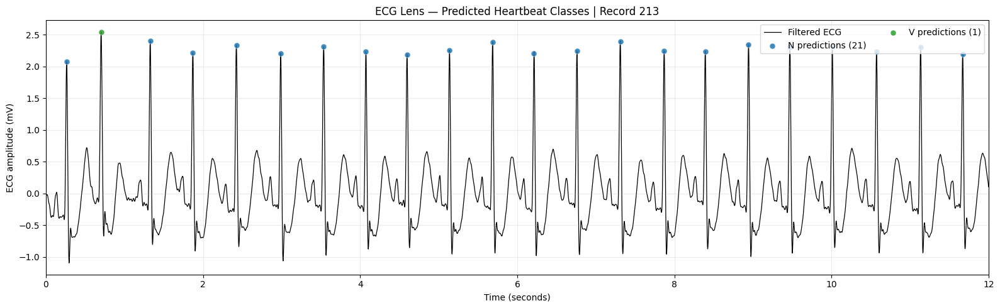

Visualised duration: 12.00 seconds
Detected beats in window: 22

Predictions in the displayed window:


,Beat count
Predicted class,
N,21
S,0
V,1
F,0


In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURE THE VISUALISATION
# ============================================================

plot_seconds = 12

n_plot_samples = min(
    int(plot_seconds * sampling_rate),
    len(ecg_filtered)
)

time_axis = np.arange(n_plot_samples) / sampling_rate

# Class colours for the plot
class_colors = {
    "N": "tab:blue",
    "S": "tab:orange",
    "V": "tab:green",
    "F": "tab:red",
}

# Use sample indices to align predictions with the ECG signal
beat_samples = np.asarray(prediction_positions, dtype=int)

visible_mask = beat_samples < n_plot_samples

visible_results = prediction_results.loc[
    visible_mask
].copy()

visible_samples = beat_samples[visible_mask]

# ============================================================
# 2. PLOT THE FILTERED ECG
# ============================================================

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    time_axis,
    ecg_filtered[:n_plot_samples],
    color="black",
    linewidth=0.9,
    label="Filtered ECG",
    zorder=1
)

# ============================================================
# 3. OVERLAY PREDICTED HEARTBEAT CLASSES
# ============================================================

for class_label in class_order:
    class_mask = (
        visible_results["ensemble_prediction"].to_numpy()
        == class_label
    )

    if not np.any(class_mask):
        continue

    class_samples = visible_samples[class_mask]
    class_times = class_samples / sampling_rate
    class_amplitudes = ecg_filtered[class_samples]

    ax.scatter(
        class_times,
        class_amplitudes,
        color=class_colors[class_label],
        label=f"{class_label} predictions ({len(class_samples)})",
        s=42,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.4,
        zorder=3
    )

ax.set_title(
    f"ECG Lens — Predicted Heartbeat Classes | Record {record_id}"
)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("ECG amplitude (mV)")
ax.set_xlim(0, n_plot_samples / sampling_rate)
ax.grid(alpha=0.25)
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

# ============================================================
# 4. SUMMARISE THE VISIBLE WINDOW
# ============================================================

print(f"Visualised duration: {n_plot_samples / sampling_rate:.2f} seconds")
print("Detected beats in window:", len(visible_results))
print("\nPredictions in the displayed window:")

display(
    visible_results["ensemble_prediction"]
    .value_counts()
    .reindex(class_order, fill_value=0)
    .rename_axis("Predicted class")
    .to_frame("Beat count")
)

## 9. Validate Against Expert ECG Annotations

We will load the expert beat annotations for held-out MIT-BIH record 213 and compare them with the automatically detected heartbeat locations.

First, we will measure beat-detection performance. Then, for detected beats that can be matched to expert annotations, we will evaluate the four-class predictions using a one-to-one matching tolerance of 100 milliseconds.

Expert annotations are used only for post-hoc evaluation—not to generate the predictions. These results apply to this recording and should not be interpreted as clinical validation.

In [29]:
import numpy as np
import pandas as pd
import wfdb

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ============================================================
# 1. LOAD EXPERT ANNOTATIONS
# ============================================================

reference_annotations = wfdb.rdann(
    record_id,
    "atr",
    pn_dir="mitdb/1.0.0"
)

reference_samples_all = np.asarray(
    reference_annotations.sample,
    dtype=int
)

reference_symbols_all = np.asarray(
    reference_annotations.symbol,
    dtype=str
)

label_mapping = model_bundle["label_mapping"]
class_order = model_bundle["class_order"]

# Keep annotations recognized by the project's saved label mapping.
known_mask = np.array([
    symbol in label_mapping
    for symbol in reference_symbols_all
])

reference_samples = reference_samples_all[known_mask]
reference_symbols = reference_symbols_all[known_mask]

reference_labels = np.array([
    label_mapping[symbol]
    for symbol in reference_symbols
])

# N, S, V, F are the classifier targets.
# Q-labelled beats remain relevant to beat detection but are excluded
# from the four-class classification metrics.
print("Record:", record_id)
print("Total expert annotations:", len(reference_samples_all))
print("Annotations recognised by project mapping:", len(reference_samples))
print("\nReference class counts, including excluded Q labels:")

display(
    pd.Series(reference_labels)
    .value_counts()
    .reindex(class_order + ["Q"], fill_value=0)
    .rename_axis("Reference class")
    .to_frame("Beat count")
)

# ============================================================
# 2. MATCH DETECTED BEATS TO EXPERT ANNOTATIONS
# ============================================================

detected_samples = np.asarray(
    prediction_positions,
    dtype=int
)

# Maximum allowed timing difference: 100 ms.
tolerance_samples = int(round(0.1 * sampling_rate))

# Each expert annotation and each detected beat can be matched
# at most once. Both arrays are in chronological order.
matched_pairs = []

i = 0  # expert annotation index
j = 0  # detected beat index

while i < len(reference_samples) and j < len(detected_samples):
    ref_sample = reference_samples[i]
    det_sample = detected_samples[j]
    difference = det_sample - ref_sample

    if abs(difference) <= tolerance_samples:
        matched_pairs.append((i, j, difference))
        i += 1
        j += 1

    elif det_sample < ref_sample - tolerance_samples:
        j += 1  # extra detection too early to match this reference

    else:
        i += 1  # expert beat was missed by the detector

matched_reference_indices = {pair[0] for pair in matched_pairs}
matched_detected_indices = {pair[1] for pair in matched_pairs}

true_positive_beats = len(matched_pairs)
false_positive_beats = len(detected_samples) - len(matched_detected_indices)
missed_reference_beats = len(reference_samples) - len(matched_reference_indices)

detection_precision = (
    true_positive_beats / len(detected_samples)
    if len(detected_samples) else 0.0
)

detection_recall = (
    true_positive_beats / len(reference_samples)
    if len(reference_samples) else 0.0
)

detection_f1 = (
    2 * detection_precision * detection_recall
    / (detection_precision + detection_recall)
    if detection_precision + detection_recall else 0.0
)

print("\nAUTOMATIC BEAT-DETECTION EVALUATION")
print("=" * 48)
print("Timing tolerance:", round(tolerance_samples / sampling_rate, 3), "seconds")
print("Reference beats:", len(reference_samples))
print("Detected beats:", len(detected_samples))
print("Matched beats:", true_positive_beats)
print("Unmatched detections:", false_positive_beats)
print("Missed reference beats:", missed_reference_beats)
print(f"Detection precision: {detection_precision:.4f}")
print(f"Detection recall:    {detection_recall:.4f}")
print(f"Detection F1:        {detection_f1:.4f}")

# ============================================================
# 3. EVALUATE CLASSIFICATION ON MATCHED BEATS
# ============================================================

evaluation_rows = []

for ref_idx, det_idx, difference in matched_pairs:
    reference_class = reference_labels[ref_idx]

    # Q is excluded from classifier scoring because the trained
    # model predicts only N, S, V, and F.
    if reference_class not in class_order:
        continue

    predicted_class = prediction_results.iloc[det_idx][
        "ensemble_prediction"
    ]

    evaluation_rows.append({
        "reference_sample": reference_samples[ref_idx],
        "detected_sample": detected_samples[det_idx],
        "timing_error_ms": difference / sampling_rate * 1000,
        "reference_symbol": reference_symbols[ref_idx],
        "reference_class": reference_class,
        "predicted_class": predicted_class
    })

matched_evaluation = pd.DataFrame(evaluation_rows)

print("\nFOUR-CLASS EVALUATION")
print("=" * 48)
print("Matched beats with N/S/V/F reference labels:",
      len(matched_evaluation))

if matched_evaluation.empty:
    print(
        "No matched beats had reference labels in N, S, V, or F. "
        "Inspect the annotation and label mapping before continuing."
    )
else:
    y_true = matched_evaluation["reference_class"]
    y_pred = matched_evaluation["predicted_class"]

    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(
    "Macro-F1:",
    f"{f1_score(y_true, y_pred, labels=class_order, average='macro', zero_division=0):.4f}"
)

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=class_order,
        zero_division=0,
        digits=3
    ))

    print("Confusion matrix (rows = reference, columns = predicted):")
    confusion = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=class_order),
        index=[f"True {label}" for label in class_order],
        columns=[f"Pred {label}" for label in class_order]
    )
    display(confusion)

    print("\nReference vs prediction sample:")
    display(matched_evaluation.head(10))

Record: 213
Total expert annotations: 3294
Annotations recognised by project mapping: 3251

Reference class counts, including excluded Q labels:


,Beat count
Reference class,
N,2641
S,28
V,220
F,362
Q,0



AUTOMATIC BEAT-DETECTION EVALUATION
Timing tolerance: 0.1 seconds
Reference beats: 3251
Detected beats: 3243
Matched beats: 3243
Unmatched detections: 0
Missed reference beats: 8
Detection precision: 1.0000
Detection recall:    0.9975
Detection F1:        0.9988

FOUR-CLASS EVALUATION
Matched beats with N/S/V/F reference labels: 3243
Accuracy: 0.8964
Macro-F1: 0.5292

Classification report:
              precision    recall  f1-score   support

           N      0.929     0.988     0.957      2640
           S      0.000     0.000     0.000        28
           V      0.633     0.981     0.770       213
           F      0.867     0.251     0.390       362

    accuracy                          0.896      3243
   macro avg      0.607     0.555     0.529      3243
weighted avg      0.894     0.896     0.873      3243

Confusion matrix (rows = reference, columns = predicted):


,Pred N,Pred S,Pred V,Pred F
True N,2607,1,20,12
True S,0,0,28,0
True V,2,0,209,2
True F,198,0,73,91



Reference vs prediction sample:


,reference_sample,detected_sample,timing_error_ms,reference_symbol,reference_class,predicted_class
0,95,95,0.000000,N,N,N
1,253,253,0.000000,N,N,V
2,478,478,0.000000,N,N,N
3,673,673,0.000000,N,N,N
4,873,873,0.000000,N,N,N
5,1076,1076,0.000000,N,N,N
6,1272,1273,2.777778,N,N,N
7,1466,1466,0.000000,N,N,N
8,1655,1655,0.000000,N,N,N
9,1849,1849,0.000000,N,N,N


## 10. Compare Individual Models Against the Voting Ensemble

We will compare Linear SVM, XGBoost, AdaBoost, and the voting ensemble on the same matched beats from held-out record 213.

We will report class-specific precision, recall, F1-score, macro-F1, and confusion matrices to identify which models are most responsible for errors in the S, V, and F classes.

In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Retrieve the evaluated reference labels
y_true = matched_evaluation["reference_class"].to_numpy()
class_order = model_bundle["class_order"]

# Map each matched detection to its row in prediction_results
sample_to_row = {
    int(sample): i
    for i, sample in enumerate(prediction_positions)
}

evaluation_indices = (
    matched_evaluation["detected_sample"]
    .map(sample_to_row)
)

if evaluation_indices.isna().any():
    raise ValueError(
        "Some matched detections could not be mapped to model predictions."
    )

evaluation_indices = evaluation_indices.astype(int).to_numpy()

# Compare all three base models and the ensemble
prediction_columns = {
    "Linear SVM": "svm_prediction",
    "XGBoost": "xgboost_prediction",
    "AdaBoost": "adaboost_prediction",
    "Voting Ensemble": "ensemble_prediction",
}

summary_rows = []

for model_name, prediction_column in prediction_columns.items():
    y_pred = (
        prediction_results.iloc[evaluation_indices][prediction_column]
        .to_numpy()
    )

    summary_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        "S recall": classification_report(
            y_true, y_pred, labels=class_order,
            output_dict=True, zero_division=0
        )["S"]["recall"],
        "F recall": classification_report(
            y_true, y_pred, labels=class_order,
            output_dict=True, zero_division=0
        )["F"]["recall"],
    })

comparison_df = pd.DataFrame(summary_rows).set_index("Model")

print("MODEL COMPARISON — RECORD 213")
display(comparison_df.round(4))

# Confusion matrices for every model on the same matched beats
for model_name, prediction_column in prediction_columns.items():
    y_pred = (
        prediction_results.iloc[evaluation_indices][prediction_column]
        .to_numpy()
    )

    print(f"\n{model_name} — confusion matrix")
    display(pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=class_order),
        index=[f"True {label}" for label in class_order],
        columns=[f"Pred {label}" for label in class_order]
    ))

MODEL COMPARISON — RECORD 213


,Accuracy,Balanced accuracy,Macro-F1,S recall,F recall
Model,,,,,
Linear SVM,0.8628,0.4167,0.4353,0.0,0.1630
XGBoost,0.5591,0.4274,0.2979,0.0,0.1298
AdaBoost,0.1588,0.4519,0.2427,0.0,0.8232
Voting Ensemble,0.8964,0.5550,0.5292,0.0,0.2514



Linear SVM — confusion matrix


,Pred N,Pred S,Pred V,Pred F
True N,2631,1,0,8
True S,27,0,1,0
True V,46,0,108,59
True F,237,0,66,59



XGBoost — confusion matrix


,Pred N,Pred S,Pred V,Pred F
True N,1555,1,1080,4
True S,0,0,28,0
True V,2,0,211,0
True F,149,0,166,47



AdaBoost — confusion matrix


,Pred N,Pred S,Pred V,Pred F
True N,8,0,21,2611
True S,0,0,28,0
True V,0,0,209,4
True F,1,0,63,298



Voting Ensemble — confusion matrix


,Pred N,Pred S,Pred V,Pred F
True N,2607,1,20,12
True S,0,0,28,0
True V,2,0,209,2
True F,198,0,73,91


## 11. Export Inference Results and Evaluation Artifacts

We will export ECG Lens predictions, matched expert-reference comparisons, model comparison metrics, and an evaluation summary.

These files will document the current inference run and provide useful artifacts for the future ECG Lens application. The saved classifiers will remain unchanged.

In [31]:
from pathlib import Path
import json
import shutil
import pandas as pd
import numpy as np

# ============================================================
# 1. CREATE OUTPUT DIRECTORY
# ============================================================

output_dir = Path("/kaggle/working/ecg_lens_inference_output")
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. EXPORT PREDICTIONS AND EVALUATION TABLES
# ============================================================

prediction_results.to_csv(
    output_dir / "record_213_predictions.csv",
    index=False
)

matched_evaluation.to_csv(
    output_dir / "record_213_matched_evaluation.csv",
    index=False
)

comparison_df.to_csv(
    output_dir / "record_213_model_comparison.csv"
)

ensemble_confusion = pd.DataFrame(
    confusion_matrix(
        matched_evaluation["reference_class"],
        matched_evaluation["predicted_class"],
        labels=model_bundle["class_order"]
    ),
    index=[
        f"True_{label}" for label in model_bundle["class_order"]
    ],
    columns=[
        f"Pred_{label}" for label in model_bundle["class_order"]
    ]
)

ensemble_confusion.to_csv(
    output_dir / "record_213_ensemble_confusion_matrix.csv"
)

# ============================================================
# 3. SAVE RUN SUMMARY
# ============================================================

summary = {
    "project": model_bundle["project_name"],
    "record_id": str(record_id),
    "model": model_bundle["model_name"],
    "features_per_beat": int(model_bundle["n_features"]),
    "detected_beats": int(len(prediction_results)),
    "reference_annotations_total": int(len(reference_samples_all)),
    "reference_annotations_recognized": int(len(reference_samples)),
    "matched_beats": int(true_positive_beats),
    "unmatched_detections": int(false_positive_beats),
    "missed_reference_beats": int(missed_reference_beats),
    "beat_detection_precision": float(detection_precision),
    "beat_detection_recall": float(detection_recall),
    "beat_detection_f1": float(detection_f1),
    "matched_beats_used_for_classification": int(
        len(matched_evaluation)
    ),
    "classification_accuracy": float(
        accuracy_score(
            matched_evaluation["reference_class"],
            matched_evaluation["predicted_class"]
        )
    ),
    "classification_macro_f1": float(
        f1_score(
            matched_evaluation["reference_class"],
            matched_evaluation["predicted_class"],
            labels=model_bundle["class_order"],
            average="macro",
            zero_division=0
        )
    ),
    "note": (
        "Single-record educational prototype evaluation. "
        "Not a clinical validation. Beat detection metrics use "
        "annotations recognised by the project's label mapping."
    )
}

with open(
    output_dir / "record_213_evaluation_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

# ============================================================
# 4. COPY MODEL BUNDLE INTO THE OUTPUT DIRECTORY
# ============================================================

if "model_path" in globals() and Path(model_path).is_file():
    shutil.copy2(
        model_path,
        output_dir / "ecg_lens_model_bundle.joblib"
    )
    print("Saved a copy of the model bundle.")

# ============================================================
# 5. VERIFY EXPORTED FILES
# ============================================================

print("\nECG LENS — EXPORTED ARTIFACTS")
print("=" * 50)

for path in sorted(output_dir.iterdir()):
    print(f"{path.name:48s} {path.stat().st_size:,} bytes")

print("\nEvaluation summary:")
print(json.dumps(summary, indent=2))

print("\nAll available inference artifacts have been exported.")

Saved a copy of the model bundle.

ECG LENS — EXPORTED ARTIFACTS
ecg_lens_model_bundle.joblib                     499,836 bytes
record_213_ensemble_confusion_matrix.csv         101 bytes
record_213_evaluation_summary.json               768 bytes
record_213_matched_evaluation.csv                85,456 bytes
record_213_model_comparison.csv                  426 bytes
record_213_predictions.csv                       97,815 bytes

Evaluation summary:
{
  "project": "ECG Lens",
  "record_id": "213",
  "model": "SVM + XGBoost + AdaBoost Voting Ensemble",
  "features_per_beat": 226,
  "detected_beats": 3243,
  "reference_annotations_total": 3294,
  "reference_annotations_recognized": 3251,
  "matched_beats": 3243,
  "unmatched_detections": 0,
  "missed_reference_beats": 8,
  "beat_detection_precision": 1.0,
  "beat_detection_recall": 0.9975392187019378,
  "beat_detection_f1": 0.9987680936248845,
  "matched_beats_used_for_classification": 3243,
  "classification_accuracy": 0.8963922294172063,
 

## 12. Reusable End-to-End Prediction Pipeline

We will combine ECG loading, preprocessing, automatic heartbeat detection, feature extraction, and ensemble classification into a reusable function.

The function uses the saved ECG Lens model bundle and does not retrain any models. Expert annotations are not used to generate predictions.

In [32]:

import numpy as np
import pandas as pd
import wfdb

from wfdb import processing
from scipy.signal import butter, sosfiltfilt
from collections import Counter


def predict_mitdb_record(record_id, pn_dir="mitdb/1.0.0"):
    """
    Run the complete ECG Lens inference pipeline on a MIT-BIH record.

    Returns the loaded signal, filtered signal, detected heartbeat
    locations, extracted features, and ensemble predictions.
    """

    # --------------------------------------------------------
    # 1. LOAD THE ECG RECORD
    # --------------------------------------------------------
    record = wfdb.rdrecord(record_id, pn_dir=pn_dir)

    lead_names = [
        str(name).strip().upper()
        for name in record.sig_name
    ]

    if "MLII" not in lead_names:
        raise ValueError(
            f"MLII lead not found in record {record_id}. "
            f"Available leads: {record.sig_name}"
        )

    lead_index = lead_names.index("MLII")
    ecg_raw = np.asarray(
        record.p_signal[:, lead_index],
        dtype=np.float64
    )

    fs = float(record.fs)
    expected_fs = float(
        model_bundle["preprocessing_config"]["sampling_rate_hz"]
    )

    if not np.isclose(fs, expected_fs):
        raise ValueError(
            f"Record sampling rate is {fs} Hz, but this model "
            f"expects {expected_fs} Hz."
        )

    if not np.isfinite(ecg_raw).all():
        raise ValueError(
            "The raw ECG contains missing or infinite values."
        )

    # --------------------------------------------------------
    # 2. FILTER THE ECG
    # --------------------------------------------------------
    config = model_bundle["preprocessing_config"]

    sos = butter(
        N=config["filter_order"],
        Wn=[
            config["low_cutoff_hz"],
            config["high_cutoff_hz"]
        ],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    ecg_filtered_local = sosfiltfilt(sos, ecg_raw)

    # --------------------------------------------------------
    # 3. AUTOMATICALLY DETECT HEARTBEATS
    # --------------------------------------------------------
    detected_positions = np.asarray(
        processing.xqrs_detect(
            sig=ecg_raw,
            fs=fs,
            verbose=False
        ),
        dtype=int
    )

    if len(detected_positions) == 0:
        raise ValueError(
            f"No heartbeats were detected in record {record_id}."
        )

    # --------------------------------------------------------
    # 4. EXTRACT THE 226 TRAINING FEATURES
    # --------------------------------------------------------
    features, valid_positions = build_beat_feature_frame(
        filtered_signal=ecg_filtered_local,
        detected_positions=detected_positions,
        sampling_rate=fs
    )

    feature_names = model_bundle["feature_names"]
    X_array = features.reindex(
        columns=feature_names
    ).to_numpy(dtype=np.float64)

    if np.isinf(X_array).any():
        raise ValueError(
            "Infinite feature values found during extraction."
        )

    if X_array.shape[1] != model_bundle["n_features"]:
        raise ValueError(
            f"Expected {model_bundle['n_features']} features, "
            f"received {X_array.shape[1]}."
        )

    # --------------------------------------------------------
    # 5. LOAD THE SAVED CLASSIFIERS AND PREDICT
    # --------------------------------------------------------
    models = model_bundle["models"]
    class_order = model_bundle["class_order"]

    svm_predictions = np.asarray(
        models["linear_svm"].predict(X_array)
    ).astype(str)

    boost_imputer = model_bundle["boost_imputer"]
    X_boost = boost_imputer.transform(X_array)

    if not np.isfinite(X_boost).all():
        raise ValueError(
            "Missing or infinite values remain after imputation."
        )

    # XGBoost was trained using integer class IDs corresponding
    # to the saved class order: N, S, V, F.
    xgb_raw = np.asarray(
        models["xgboost"].predict(X_boost)
    ).reshape(-1)

    xgb_predictions = []

    for value in xgb_raw:
        label = str(value)

        if label in class_order:
            xgb_predictions.append(label)
            continue

        try:
            numeric_value = float(value)
            class_index = int(numeric_value)

            if (
                numeric_value.is_integer()
                and 0 <= class_index < len(class_order)
            ):
                xgb_predictions.append(
                    class_order[class_index]
                )
                continue
        except (TypeError, ValueError, OverflowError):
            pass

        raise ValueError(
            f"Could not decode XGBoost prediction {value!r}."
        )

    xgb_predictions = np.asarray(xgb_predictions, dtype=str)

    ada_predictions = np.asarray(
        models["adaboost"].predict(X_boost)
    ).astype(str)

    # --------------------------------------------------------
    # 6. APPLY THE SAVED MAJORITY-VOTING RULE
    # --------------------------------------------------------
    ensemble_predictions = []

    for svm_label, xgb_label, ada_label in zip(
        svm_predictions,
        xgb_predictions,
        ada_predictions
    ):
        counts = Counter([
            svm_label,
            xgb_label,
            ada_label
        ])

        highest_count = max(counts.values())

        tied_classes = [
            label for label in class_order
            if counts[label] == highest_count
        ]

        if len(tied_classes) == 1:
            final_label = tied_classes[0]
        elif svm_label in tied_classes:
            final_label = svm_label
        else:
            final_label = tied_classes[0]

        ensemble_predictions.append(final_label)

    # --------------------------------------------------------
    # 7. BUILD RESULTS
    # --------------------------------------------------------
    results = pd.DataFrame({
        "beat_index": np.arange(1, len(features) + 1),
        "time_seconds": np.asarray(valid_positions) / fs,
        "svm_prediction": svm_predictions,
        "xgboost_prediction": xgb_predictions,
        "adaboost_prediction": ada_predictions,
        "ensemble_prediction": ensemble_predictions
    })

    return {
        "record_id": str(record_id),
        "lead": record.sig_name[lead_index],
        "sampling_rate": fs,
        "raw_signal": ecg_raw,
        "filtered_signal": ecg_filtered_local,
        "detected_positions": detected_positions,
        "prediction_positions": np.asarray(valid_positions),
        "features": features,
        "predictions": results
    }


print("Reusable ECG Lens prediction function is ready.")


Reusable ECG Lens prediction function is ready.


In [ ]:
record213_run = predict_mitdb_record("213")

print("Record:", record213_run["record_id"])
print("Lead:", record213_run["lead"])
print("Sampling rate:", record213_run["sampling_rate"], "Hz")
print("Feature matrix:", record213_run["features"].shape)
print("Heartbeats classified:", len(record213_run["predictions"]))

print("\nPredicted class counts:")
display(
    record213_run["predictions"]["ensemble_prediction"]
    .value_counts()
    .reindex(
        model_bundle["class_order"],
        fill_value=0
    )
    .rename_axis("Class")
    .to_frame("Beat count")
)

print("\nFirst 10 predictions:")
display(record213_run["predictions"].head(10))

## 14. Full-Record ECG Prediction Viewer

This section visualises the complete selected ECG recording alongside ECG Lens's predicted heartbeat classes. An interactive timeline allows exploration of different portions of the signal, while a scrollable prediction table provides the timestamp, individual model predictions, and final ensemble prediction for every detected heartbeat with a complete feature window.

The displayed classifications are model predictions, not confirmed clinical diagnoses.

In [35]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go

from IPython.display import display, HTML

# ============================================================
# 1. LOAD THE COMPLETE RECORD'S RESULTS
# ============================================================

run = record213_run

signal = np.asarray(run["filtered_signal"])
fs = float(run["sampling_rate"])
beat_positions = np.asarray(run["prediction_positions"])

predictions = run["predictions"].copy()
class_order = model_bundle["class_order"]

assert len(beat_positions) == len(predictions)

record_duration = len(signal) / fs

print("ECG LENS — FULL RECORD VIEWER")
print("=" * 55)
print("Record:", run["record_id"])
print("Lead:", run["lead"])
print(f"Duration: {record_duration / 60:.2f} minutes")
print("Total ECG samples:", f"{len(signal):,}")
print("Predicted heartbeats:", f"{len(predictions):,}")

# ============================================================
# 2. INTERACTIVE FULL-RECORD ECG TIMELINE
# ============================================================

# Limit waveform points to keep the interactive plot responsive.
# Beat markers still use their exact sample locations.
max_wave_points = 100_000
plot_stride = max(
    1,
    int(np.ceil(len(signal) / max_wave_points))
)

wave_samples = np.arange(0, len(signal), plot_stride)
wave_times = wave_samples / fs

fig = go.Figure()

# Filtered ECG waveform
fig.add_trace(
    go.Scattergl(
        x=wave_times,
        y=signal[wave_samples],
        mode="lines",
        name="Filtered ECG",
        line=dict(color="#344054", width=0.8),
        hovertemplate=(
            "Time: %{x:.2f} s<br>"
            "Amplitude: %{y:.3f} mV"
            "<extra>Filtered ECG</extra>"
        )
    )
)

# Predicted heartbeat markers
class_colors = {
    "N": "#3984D6",
    "S": "#E5A23B",
    "V": "#2DA879",
    "F": "#D95757",
}

predicted_labels = predictions[
    "ensemble_prediction"
].to_numpy()

for class_label in class_order:
    mask = predicted_labels == class_label

    if not mask.any():
        continue

    class_samples = beat_positions[mask]

    fig.add_trace(
        go.Scattergl(
            x=class_samples / fs,
            y=signal[class_samples],
            mode="markers",
            name=f"{class_label} predictions",
            marker=dict(
                color=class_colors.get(class_label, "#777777"),
                size=6,
                opacity=0.85
            ),
            customdata=np.column_stack([
                predictions.loc[mask, "beat_index"].to_numpy(),
                predictions.loc[mask, "svm_prediction"].to_numpy(),
                predictions.loc[mask, "xgboost_prediction"].to_numpy(),
                predictions.loc[mask, "adaboost_prediction"].to_numpy()
            ]),
            hovertemplate=(
                "Time: %{x:.3f} s<br>"
                "Amplitude: %{y:.3f} mV<br>"
                "Beat index: %{customdata[0]}<br>"
                "SVM: %{customdata[1]}<br>"
                "XGBoost: %{customdata[2]}<br>"
                "AdaBoost: %{customdata[3]}<br>"
                f"Ensemble: {class_label}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title=f"ECG Lens — Complete ECG Record {run['record_id']}",
    xaxis=dict(
        title="Time (seconds)",
        rangeslider=dict(visible=True, thickness=0.08),
        showgrid=True
    ),
    yaxis=dict(
        title="ECG amplitude (mV)",
        showgrid=True
    ),
    height=600,
    hovermode="closest",
    dragmode="pan",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=65, r=25, t=100, b=65)
)

print("\nInteractive ECG timeline:")
display(fig)

# ============================================================
# 3. SUMMARY OF THE COMPLETE RECORD
# ============================================================

summary_counts = (
    predictions["ensemble_prediction"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

summary_table = pd.DataFrame({
    "Predicted class": class_order,
    "Heartbeat count": [
        int(summary_counts[label]) for label in class_order
    ],
})

summary_table["Percentage"] = (
    100 * summary_table["Heartbeat count"]
    / max(len(predictions), 1)
).round(2)

print("\nFull-record prediction summary:")
display(summary_table)

# ============================================================
# 4. FULL PREDICTION TABLE IN A SCROLLABLE CONTAINER
# ============================================================

table_df = predictions.copy()

table_df["time_minutes"] = (
    table_df["time_seconds"] / 60
).round(3)

table_df = table_df[
    [
        "beat_index",
        "time_seconds",
        "time_minutes",
        "svm_prediction",
        "xgboost_prediction",
        "adaboost_prediction",
        "ensemble_prediction"
    ]
].copy()

table_html = table_df.to_html(
    index=False,
    escape=True,
    border=0,
    classes="ecg-lens-scroll-table",
    float_format=lambda value: f"{value:.3f}"
)

scrollable_html = f"""
<div style="
    border: 1px solid #D0D5DD;
    border-radius: 10px;
    margin: 12px 0;
    overflow-x: auto;
">
  <div style="
      max-height: 520px;
      overflow-y: auto;
      overflow-x: auto;
  ">
    <style>
      .ecg-lens-scroll-table {{
          width: 100%;
          border-collapse: separate;
          border-spacing: 0;
          font-family: Arial, sans-serif;
          font-size: 13px;
      }}

      .ecg-lens-scroll-table th {{
          position: sticky;
          top: 0;
          z-index: 2;
          background: #27364B;
          color: white;
          padding: 10px;
          text-align: left;
          white-space: nowrap;
      }}

      .ecg-lens-scroll-table td {{
          padding: 8px 10px;
          border-bottom: 1px solid #EAECF0;
          white-space: nowrap;
      }}

      .ecg-lens-scroll-table tbody tr:nth-child(even) {{
          background: #F7F9FC;
      }}

      .ecg-lens-scroll-table tbody tr:hover {{
          background: #EAF2FF;
      }}
    </style>

    {table_html}
  </div>
</div>
"""

print(
    f"\nAll {len(table_df):,} heartbeat predictions "
    "are available in the scrollable table below."
)

display(HTML(scrollable_html))


ECG LENS — FULL RECORD VIEWER
Record: 213
Lead: MLII
Duration: 30.09 minutes
Total ECG samples: 650,000
Predicted heartbeats: 3,243

Interactive ECG timeline:



Full-record prediction summary:


,Predicted class,Heartbeat count,Percentage
0,N,2807,86.56
1,S,1,0.03
2,V,330,10.18
3,F,105,3.24



All 3,243 heartbeat predictions are available in the scrollable table below.


beat_index,time_seconds,time_minutes,svm_prediction,xgboost_prediction,adaboost_prediction,ensemble_prediction
1,0.264,0.004,N,N,F,N
2,0.703,0.012,N,V,V,V
3,1.328,0.022,N,N,F,N
4,1.869,0.031,N,V,F,N
5,2.425,0.040,N,N,F,N
6,2.989,0.050,N,N,F,N
7,3.536,0.059,N,V,F,N
8,4.072,0.068,N,V,F,N
9,4.597,0.077,N,V,F,N
10,5.136,0.086,N,V,F,N


In [36]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go

from IPython.display import display, HTML

# ============================================================
# 1. LOAD THE EXISTING FULL-RECORD PREDICTIONS
# ============================================================

if "record213_run" not in globals():
    raise NameError(
        "record213_run was not found. Run the prediction cell first."
    )

run = record213_run

ecg_signal = np.asarray(run["filtered_signal"])
fs = float(run["sampling_rate"])
beat_positions = np.asarray(run["prediction_positions"], dtype=int)
predictions = run["predictions"].reset_index(drop=True)

if len(beat_positions) != len(predictions):
    raise ValueError(
        "Heartbeat positions and prediction rows do not match."
    )

duration_seconds = len(ecg_signal) / fs
time_minutes = duration_seconds / 60

print(f"Record: {run['record_id']}")
print(f"Duration: {time_minutes:.2f} minutes")
print(f"Heartbeats classified: {len(predictions):,}")
print("Preparing complete-record timeline...")

# ============================================================
# 2. PREPARE A LIGHTWEIGHT WAVEFORM OVERVIEW
# ============================================================

# Limit waveform points to keep Plotly responsive.
# Prediction markers retain their exact sample positions.
max_wave_points = 60000
stride = max(1, int(np.ceil(len(ecg_signal) / max_wave_points)))

wave_indices = np.arange(0, len(ecg_signal), stride)
wave_times = wave_indices / fs
wave_amplitudes = ecg_signal[wave_indices]

# ============================================================
# 3. CREATE THE INTERACTIVE FULL-RECORD FIGURE
# ============================================================

class_colors = {
    "N": "#3984D6",
    "S": "#E5A23B",
    "V": "#2DA879",
    "F": "#D95757",
}

class_order = model_bundle["class_order"]

fig = go.Figure()

# Entire recording overview
fig.add_trace(
    go.Scattergl(
        x=wave_times,
        y=wave_amplitudes,
        mode="lines",
        name="Filtered ECG",
        line=dict(color="#667085", width=0.7),
        hovertemplate=(
            "Time: %{x:.2f} seconds<br>"
            "Amplitude: %{y:.3f} mV"
            "<extra>ECG signal</extra>"
        )
    )
)

# Overlay every retained heartbeat prediction
for label in class_order:
    mask = (
        predictions["ensemble_prediction"].to_numpy() == label
    )

    if not mask.any():
        continue

    positions_for_class = beat_positions[mask]
    rows_for_class = predictions.loc[mask]

    custom_data = rows_for_class[
        [
            "beat_index",
            "svm_prediction",
            "xgboost_prediction",
            "adaboost_prediction"
        ]
    ].to_numpy()

    fig.add_trace(
        go.Scattergl(
            x=positions_for_class / fs,
            y=ecg_signal[positions_for_class],
            mode="markers",
            name=f"{label} predicted ({int(mask.sum())})",
            marker=dict(
                color=class_colors[label],
                size=6,
                opacity=0.9
            ),
            customdata=custom_data,
            hovertemplate=(
                "Time: %{x:.3f} seconds<br>"
                "Amplitude: %{y:.3f} mV<br>"
                "Beat #: %{customdata[0]}<br>"
                "SVM: %{customdata[1]}<br>"
                "XGBoost: %{customdata[2]}<br>"
                "AdaBoost: %{customdata[3]}<br>"
                f"Ensemble: {label}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title=(
        f"ECG Lens | Record {run['record_id']} — "
        f"Full ECG Timeline ({time_minutes:.1f} minutes)"
    ),
    xaxis=dict(
        title="Time (seconds)",
        rangeslider=dict(visible=True, thickness=0.10),
        showgrid=True
    ),
    yaxis=dict(
        title="ECG amplitude (mV)",
        showgrid=True
    ),
    height=650,
    hovermode="closest",
    dragmode="pan",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=65, r=25, t=110, b=70)
)

# ============================================================
# 4. FORCE INLINE DISPLAY IN KAGGLE
# ============================================================

# Embed Plotly's JavaScript so the chart doesn't depend on a CDN.
html = fig.to_html(
    full_html=False,
    include_plotlyjs=True,
    config={
        "responsive": True,
        "scrollZoom": True,
        "displaylogo": False
    }
)

display(HTML(html))

print("\nInteractive timeline rendered.")


Record: 213
Duration: 30.09 minutes
Heartbeats classified: 3,243
Preparing complete-record timeline...



Interactive timeline rendered.


In [37]:

import numpy as np
import plotly.graph_objects as go
from IPython.display import display, HTML

# ============================================================
# 1. LOAD EXISTING PREDICTION RESULTS
# ============================================================

if "record213_run" not in globals():
    raise NameError("Run the prediction cell that creates record213_run first.")

run = record213_run

signal = np.asarray(run["filtered_signal"])
fs = float(run["sampling_rate"])
beat_positions = np.asarray(run["prediction_positions"], dtype=int)
predictions = run["predictions"].reset_index(drop=True)
class_order = model_bundle["class_order"]

duration = len(signal) / fs

if len(beat_positions) != len(predictions):
    raise ValueError("Heartbeat positions and predictions do not match.")

# ============================================================
# 2. CONFIGURE THE PLAYBACK
# ============================================================

WINDOW_SECONDS = 10  # Each view advances through a 10-second window

max_wave_points = 60000
stride = max(1, int(np.ceil(len(signal) / max_wave_points)))

wave_samples = np.arange(0, len(signal), stride)
wave_times = wave_samples / fs
wave_values = signal[wave_samples]

# Keep the playback cursor visible across the full amplitude range
y_min = float(np.min(signal))
y_max = float(np.max(signal))
y_padding = max((y_max - y_min) * 0.08, 0.01)
y_range = [y_min - y_padding, y_max + y_padding]

class_colors = {
    "N": "#3984D6",
    "S": "#E5A23B",
    "V": "#2DA879",
    "F": "#D95757",
}

# ============================================================
# 3. BUILD THE FULL-RECORD TIMELINE
# ============================================================

fig = go.Figure()

# Waveform overview
fig.add_trace(
    go.Scattergl(
        x=wave_times,
        y=wave_values,
        mode="lines",
        name="Filtered ECG",
        line=dict(color="#667085", width=0.8),
        hovertemplate=(
            "Time: %{x:.2f} seconds<br>"
            "Amplitude: %{y:.3f} mV"
            "<extra>ECG</extra>"
        )
    )
)

# Heartbeat markers for each predicted class
for label in class_order:
    mask = (
        predictions["ensemble_prediction"].to_numpy() == label
    )

    if not np.any(mask):
        continue

    samples = beat_positions[mask]
    class_rows = predictions.loc[mask]

    hover_data = np.column_stack([
        class_rows["beat_index"].to_numpy(),
        class_rows["svm_prediction"].to_numpy(),
        class_rows["xgboost_prediction"].to_numpy(),
        class_rows["adaboost_prediction"].to_numpy()
    ])

    fig.add_trace(
        go.Scattergl(
            x=samples / fs,
            y=signal[samples],
            mode="markers",
            name=f"{label} predicted",
            marker=dict(
                color=class_colors[label],
                size=6,
                opacity=0.9
            ),
            customdata=hover_data,
            hovertemplate=(
                "Time: %{x:.3f} seconds<br>"
                "Beat: %{customdata[0]}<br>"
                "SVM: %{customdata[1]}<br>"
                "XGBoost: %{customdata[2]}<br>"
                "AdaBoost: %{customdata[3]}<br>"
                f"Ensemble: {label}"
                "<extra></extra>"
            )
        )
    )

# Moving vertical playback cursor
fig.add_trace(
    go.Scatter(
        x=[0, 0],
        y=y_range,
        mode="lines",
        name="Playback cursor",
        line=dict(color="#202939", width=2, dash="dash"),
        hoverinfo="skip"
    )
)

cursor_trace_index = len(fig.data) - 1

# ============================================================
# 4. CREATE ANIMATION FRAMES
# ============================================================

number_of_frames = int(np.ceil(duration / WINDOW_SECONDS))
frames = []

for frame_index in range(number_of_frames):
    start = frame_index * WINDOW_SECONDS
    end = min(start + WINDOW_SECONDS, duration)

    frames.append(
        go.Frame(
            name=f"frame_{frame_index}",
            data=[
                go.Scatter(
                    x=[start, start],
                    y=y_range
                )
            ],
            traces=[cursor_trace_index],
            layout=go.Layout(
                xaxis=dict(
                    range=[start, end],
                    autorange=False
                ),
                title=dict(
                    text=(
                        f"ECG Lens — Record {run['record_id']} | "
                        f"{start:.0f}–{end:.0f} seconds"
                    )
                )
            )
        )
    )

fig.frames = frames

# ============================================================
# 5. ADD PLAY / PAUSE / SPEED CONTROLS
# ============================================================

def play_button(label, frame_duration):
    return dict(
        label=label,
        method="animate",
        args=[
            None,
            {
                "mode": "immediate",
                "fromcurrent": True,
                "frame": {
                    "duration": frame_duration,
                    "redraw": False
                },
                "transition": {"duration": 0}
            }
        ]
    )

pause_button = dict(
    label="⏸ Pause",
    method="animate",
    args=[
        [None],
        {
            "mode": "immediate",
            "frame": {"duration": 0, "redraw": False},
            "transition": {"duration": 0}
        }
    ]
)

fig.update_layout(
    title=(
        f"ECG Lens — Record {run['record_id']} | "
        f"0–{min(WINDOW_SECONDS, duration):.0f} seconds"
    ),
    xaxis=dict(
        title="Time (seconds)",
        range=[0, min(WINDOW_SECONDS, duration)],
        rangeslider=dict(visible=True, thickness=0.09),
        showgrid=True
    ),
    yaxis=dict(
        title="ECG amplitude (mV)",
        range=y_range,
        showgrid=True
    ),
    height=680,
    hovermode="closest",
    dragmode="pan",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.08,
        xanchor="left",
        x=0
    ),
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            showactive=False,
            x=0,
            y=1.20,
            xanchor="left",
            yanchor="top",
            buttons=[
                play_button("▶ Play", 500),
                pause_button,
                play_button("▶ 2×", 250),
                play_button("▶ 4×", 125),
            ]
        )
    ],
    margin=dict(l=65, r=25, t=145, b=75)
)

# ============================================================
# 6. RENDER INTERACTIVELY IN KAGGLE
# ============================================================

print(f"Record duration: {duration / 60:.2f} minutes")
print(f"Heartbeat predictions: {len(predictions):,}")
print(f"Playback windows: {number_of_frames}")
print("Rendering interactive playback timeline...")

html = fig.to_html(
    full_html=False,
    include_plotlyjs=True,
    auto_play=False,
    config={
        "responsive": True,
        "scrollZoom": True,
        "displaylogo": False
    }
)

display(HTML(html))


Record duration: 30.09 minutes
Heartbeat predictions: 3,243
Playback windows: 181
Rendering interactive playback timeline...
